**IRANIAN CHURN ANALYSIS**

**OBJECTIVES:**

•To identify how customer dissatisfied, service usage levels, and specific demographics drive subscription cancellations.

•Implement predictive modeling to flag subscribers at high risk of leaving.

•Evaluate variables such as call failures, complaints, subscription length, and frequency of use to understand engagement patterns.

•Provide actionable insights for telecom operators to design targeted onboarding and pricing interventions.




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df=pd.DataFrame()

In [ ]:
df=pd.read_csv("/content/Customer Churn.csv")

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [ ]:
df.shape

(3150, 14)

In [ ]:
df.head()


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [ ]:
df.describe()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
count,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000,3150.000000
mean,7.627937,0.076508,32.541905,0.942857,4472.459683,69.460635,73.174921,23.509841,2.826032,1.077778,1.248254,30.998413,470.972916,0.157143
std,7.263886,0.265851,8.573482,1.521072,4197.908687,57.413308,112.237560,17.217337,0.892555,0.267864,0.432069,8.831095,517.015433,0.363993
min,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,15.000000,0.000000,0.000000
25%,1.000000,0.000000,30.000000,0.000000,1391.250000,27.000000,6.000000,10.000000,2.000000,1.000000,1.000000,25.000000,113.801250,0.000000
50%,6.000000,0.000000,35.000000,0.000000,2990.000000,54.000000,21.000000,21.000000,3.000000,1.000000,1.000000,30.000000,228.480000,0.000000
75%,12.000000,0.000000,38.000000,1.000000,6478.250000,95.000000,87.000000,34.000000,3.000000,1.000000,1.000000,30.000000,788.388750,0.000000
max,36.000000,1.000000,47.000000,10.000000,17090.000000,255.000000,522.000000,97.000000,5.000000,2.000000,2.000000,55.000000,2165.280000,1.000000


In [ ]:
df.dtypes

,0
Call Failure,int64
Complains,int64
Subscription Length,int64
Charge Amount,int64
Seconds of Use,int64
Frequency of use,int64
Frequency of SMS,int64
Distinct Called Numbers,int64
Age Group,int64
Tariff Plan,int64


In [ ]:
df.tail()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
3145,21,0,19,2,6697,147,92,44,2,2,1,25,721.98,0
3146,17,0,17,1,9237,177,80,42,5,1,1,55,261.21,0
3147,13,0,18,4,3157,51,38,21,3,1,1,30,280.32,0
3148,7,0,11,2,4695,46,222,12,3,1,1,30,1077.64,0
3149,8,1,11,2,1792,25,7,9,3,1,1,30,100.68,1


In [ ]:
df.isnull().sum()


,0
Call Failure,0
Complains,0
Subscription Length,0
Charge Amount,0
Seconds of Use,0
Frequency of use,0
Frequency of SMS,0
Distinct Called Numbers,0
Age Group,0
Tariff Plan,0


In [ ]:
df.duplicated().sum()

np.int64(300)

In [ ]:
duplicate_rows = df[df.duplicated(keep=False)]
display(duplicate_rows.sort_values(by=list(df.columns)).head(10))

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
2049,0,0,7,0,1182,13,0,5,2,1,1,25,53.775,1
2099,0,0,7,0,1182,13,0,5,2,1,1,25,53.775,1
1098,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
2048,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
2098,0,0,7,0,4085,34,208,8,3,1,1,30,996.760,0
1094,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
2044,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
2094,0,0,16,0,1390,20,21,12,2,1,1,25,157.950,0
1691,0,0,23,0,0,0,0,0,4,1,2,45,0.000,0
1991,0,0,23,0,0,0,0,0,4,1,2,45,0.000,0


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.shape

(2850, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2850 entries, 0 to 3131
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            2850 non-null   int64  
 1   Complains                2850 non-null   int64  
 2   Subscription  Length     2850 non-null   int64  
 3   Charge  Amount           2850 non-null   int64  
 4   Seconds of Use           2850 non-null   int64  
 5   Frequency of use         2850 non-null   int64  
 6   Frequency of SMS         2850 non-null   int64  
 7   Distinct Called Numbers  2850 non-null   int64  
 8   Age Group                2850 non-null   int64  
 9   Tariff Plan              2850 non-null   int64  
 10  Status                   2850 non-null   int64  
 11  Age                      2850 non-null   int64  
 12  Customer Value           2850 non-null   float64
 13  Churn                    2850 non-null   int64  
dtypes: float64(1), int64(13)
memo

In [ ]:
# Change the Status column values and convert datatype to string
status_mapping = {1: 'ACTIVE', 2: 'NON-ACTIVE'}
df['Status'] = df['Status'].map(status_mapping).astype(str)

# Display the unique values and first few rows to verify the transformation
print("Unique values in Status:", df['Status'].unique())
display(df[['Status']].head())

Unique values in Status: ['ACTIVE' 'NON-ACTIVE']


,Status
0,ACTIVE
1,NON-ACTIVE
2,ACTIVE
3,ACTIVE
4,ACTIVE


In [ ]:
# Calculate correlation only for numeric columns to avoid string conversion errors
df.corr(numeric_only=True)

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Age,Customer Value,Churn
Call Failure,1.000000,0.149564,0.177206,0.585442,0.495463,0.567096,-0.031926,0.498604,0.049340,0.187537,0.043799,0.110228,0.003310
Complains,0.149564,1.000000,-0.019229,-0.035887,-0.108934,-0.095519,-0.114729,-0.061314,0.015761,0.002461,-0.000400,-0.136989,0.546055
Subscription Length,0.177206,-0.019229,1.000000,0.084275,0.127184,0.109148,0.080530,0.099215,0.030078,-0.160538,0.005900,0.113184,-0.037984
Charge Amount,0.585442,-0.035887,0.084275,1.000000,0.443585,0.372646,0.085781,0.413897,0.282761,0.321193,0.283466,0.161852,-0.201662
Seconds of Use,0.495463,-0.108934,0.127184,0.443585,1.000000,0.945144,0.093073,0.671973,0.015253,0.127793,0.019383,0.408536,-0.295999
Frequency of use,0.567096,-0.095519,0.109148,0.372646,0.945144,1.000000,0.090712,0.731204,-0.039523,0.199873,-0.031574,0.394647,-0.298608
Frequency of SMS,-0.031926,-0.114729,0.080530,0.085781,0.093073,0.090712,1.000000,0.069717,-0.056859,0.193785,-0.093235,0.922852,-0.218894
Distinct Called Numbers,0.498604,-0.061314,0.099215,0.413897,0.671973,0.731204,0.069717,1.000000,0.015562,0.167037,0.049187,0.275447,-0.270343
Age Group,0.049340,0.015761,0.030078,0.282761,0.015253,-0.039523,-0.056859,0.015562,1.000000,-0.153496,0.960877,-0.193461,-0.005891
Tariff Plan,0.187537,0.002461,-0.160538,0.321193,0.127793,0.199873,0.193785,0.167037,-0.153496,1.000000,-0.120429,0.249999,-0.106000


In [ ]:
skewness = df.skew(numeric_only=True)
display(skewness)

,0
Call Failure,1.067233
Complains,3.080435
Subscription Length,-1.252843
Charge Amount,2.533804
Seconds of Use,1.314737
Frequency of use,1.145862
Frequency of SMS,1.971020
Distinct Called Numbers,1.039277
Age Group,0.453043
Tariff Plan,3.089147


VISUALIZATION

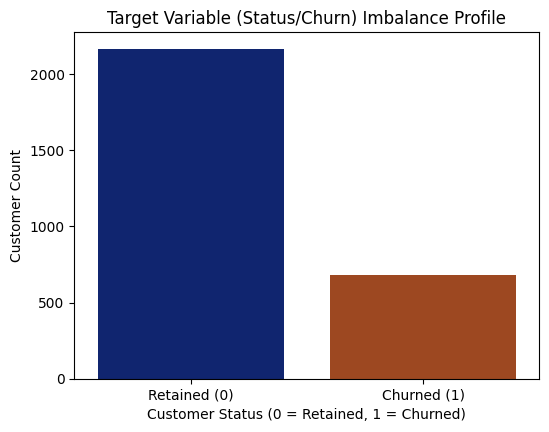

In [ ]:
#Univariate Analysis
# 1: Target Class Count Plot
plt.figure(figsize=(6, 4.5))
sns.countplot(x='Status', data=df, hue='Status', palette='dark', legend=False)
plt.title('Target Variable (Status/Churn) Imbalance Profile')
plt.xlabel('Customer Status (0 = Retained, 1 = Churned)')
plt.ylabel('Customer Count')
plt.xticks([0, 1], ['Retained (0)', 'Churned (1)'])
plt.show()

**• Why it is used:** To visually evaluate the baseline macro-split of the
prediction column (Churn).

**• Interpretation:** Out of 3,150 customer traces, ~84% are labeled Retained (0) while ~16% are labeled Churned (1).

**• Business Insight:** The company is suffering an acute structural attrition problem. However, because the dataset displays an 84/16 class   imbalance, a predictive model could lazily guess "Retained" every time and look 84% accurate. Data engineering teams must discard default Accuracy metrics and use Recall or F1-Score to train predictive algorithms.

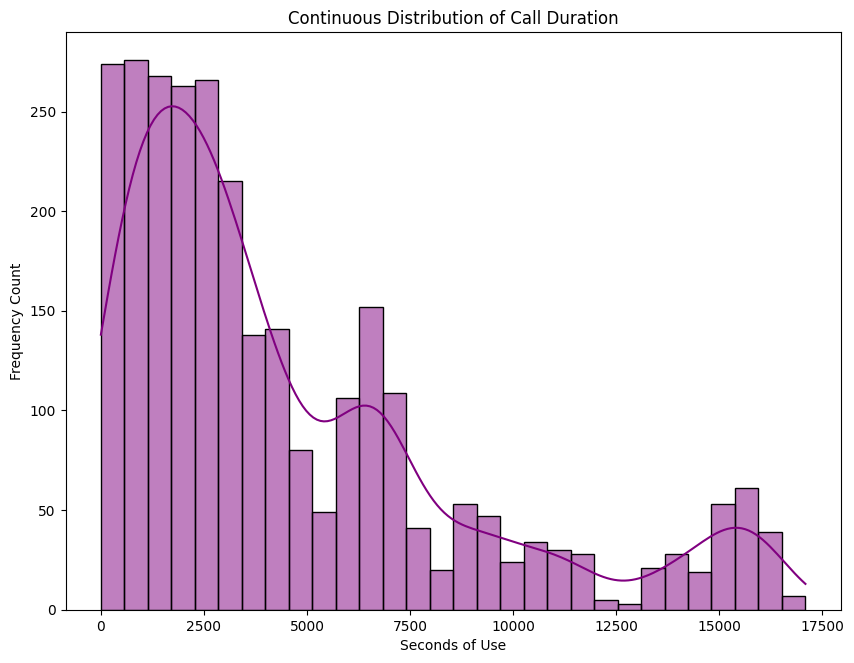

In [ ]:
# 2: Seconds of Use Histogram
plt.figure(figsize=(10, 7.5))
sns.histplot(df['Seconds of Use'], color='purple', bins=30, kde=True)
plt.title('Continuous Distribution of Call Duration')
plt.xlabel('Seconds of Use')
plt.ylabel('Frequency Count')
plt.show()



**• Why it is used:** To evaluate continuous feature range limits and uncover underlying geometric shapes.

**• Interpretation:** The visualization forms a steep, heavily right-skewed curve peaking dramatically at 0 to 1,500 seconds, with an exponentially shrinking tail.

**• Business Insight:** The overwhelming majority of subscribers display low-to-moderate monthly calling traffic. A tiny tier of hyper-active premium users commands the long right tail. Distance-based algorithms (like KNN or SVM) will suffer heavily from outlier bias here unless normalized with log transforms or a RobustScaler.


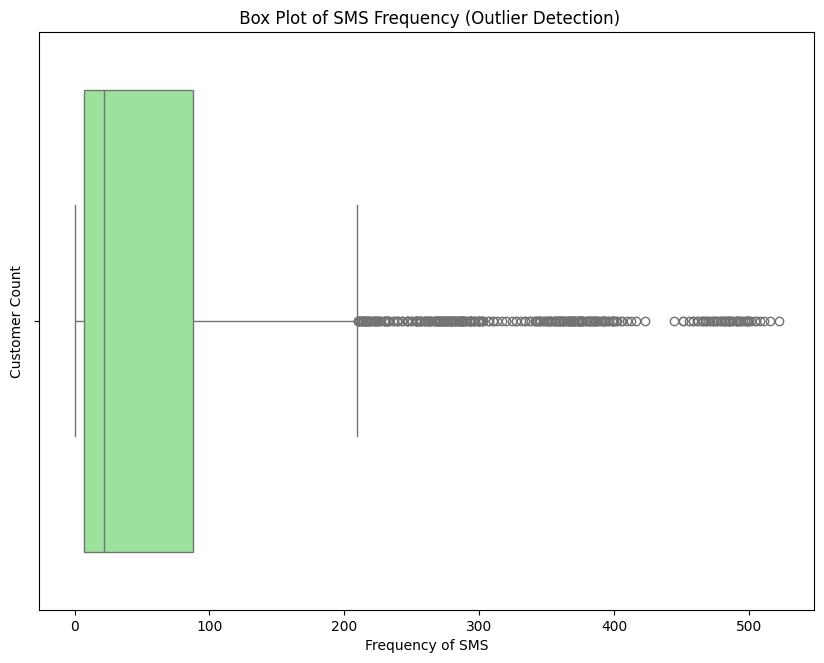

In [ ]:
# 3: Frequency of SMS Box Plot
plt.figure(figsize=(10, 7.5))
sns.boxplot(x=df['Frequency of SMS'], color='lightgreen')
plt.title(' Box Plot of SMS Frequency (Outlier Detection)')
plt.xlabel('Frequency of SMS')
plt.ylabel('Customer Count')
plt.show()



**• Why it is used:** To calculate the central median line and explicitly flag the density of extreme distribution outliers.

**• Interpretation:** The box boundary is compressed firmly toward the lower limits, while dozens of discrete data points float far past the maximum interquartile range (IQR) line.

**• Business Insight:** While normal clients text sparingly, specific enterprise accounts or automated text bots skew raw distribution bounds. These maximum outliers must be trimmed using Tukey’s fences or IQR capping to ensure baseline model stability.

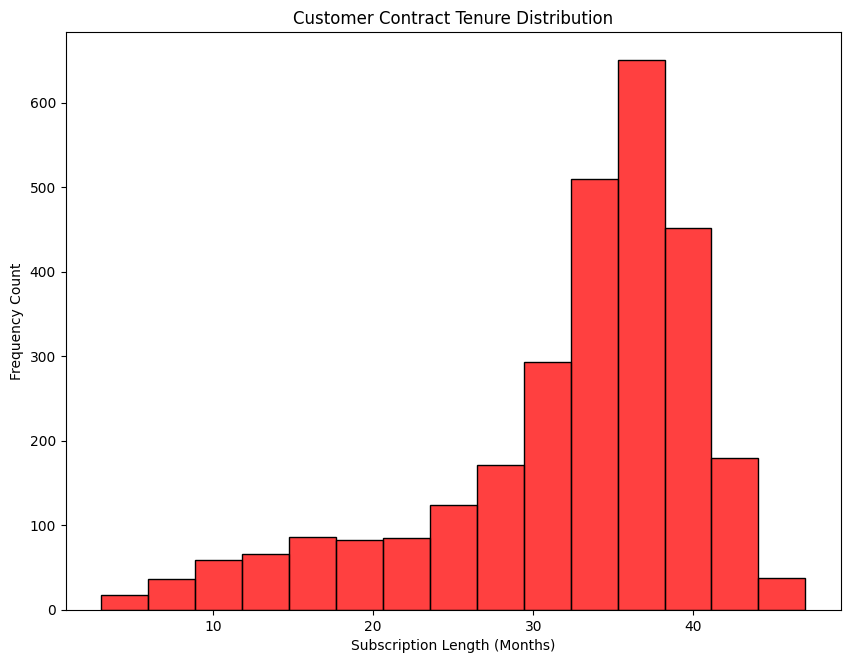

In [ ]:
# 4: Subscription Length Tenure Distribution
plt.figure(figsize=(10, 7.5))
sns.histplot(df['Subscription  Length'], kde=False, color='red', bins=15)
plt.title('Customer Contract Tenure Distribution')
plt.xlabel('Subscription Length (Months)')
plt.ylabel('Frequency Count')
plt.show()



**• Why it is used:** To calculate the central median line and explicitly flag the density of extreme distribution outliers.

**• Interpretation:** The box boundary is compressed firmly toward the lower limits, while dozens of discrete data points float far past the maximum interquartile range (IQR) line.

**• Business Insight:** While normal clients text sparingly, specific enterprise accounts or automated text bots skew raw distribution bounds. These maximum outliers must be trimmed using Tukey’s fences or IQR capping to ensure baseline model stability.


**• Why it is used:** To observe user tenure patterns over historical registration blocks.

**• Interpretation:** The data shows a largely uniform spread with slight, intentional frequency bumps visible at the 12-month and 24-month marks.

**• Business Insight:** Acquisition channels have remained reliable over time. The small bumps at full-year increments indicate standard contract expiration dates where consumers are forced to decide whether to renew or drop the network.

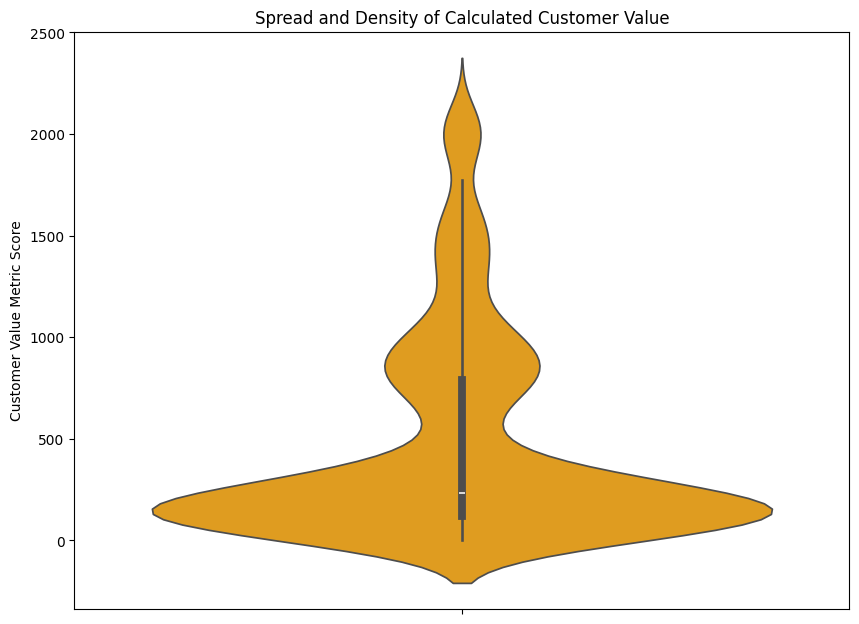

In [ ]:
# 5: Customer Value Violin Plot
plt.figure(figsize=(10, 7.5))
sns.violinplot(y=df['Customer Value'], color='orange')
plt.title('Spread and Density of Calculated Customer Value')
plt.ylabel('Customer Value Metric Score')
plt.show()



**• Why it is used:** To observe both the central trend density and the full continuous dispersion shape simultaneously.

**• Interpretation:** The violin shape has a thick bulge at the lower tier but reveals an extended, needle-like tail stretching up into premium customer valuation spaces.

**• Business Insight:** While the general population generates steady, low-yield returns, a narrow segment of premium clients represents the real financial cushion of this provider. Losing even a few of these users will hit overall profitability hard.

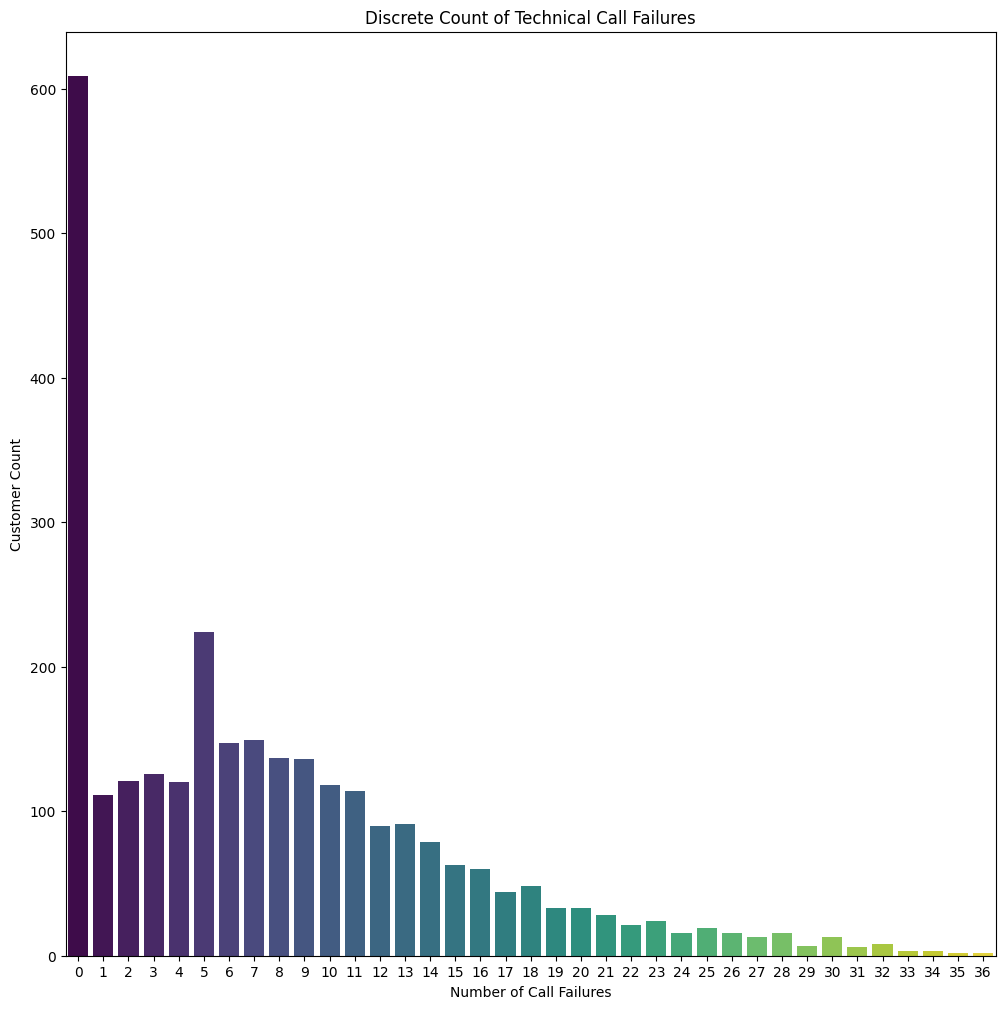

In [ ]:
# 6: Call Failures Discrete Count Plot
plt.figure(figsize=(12, 12))
sns.countplot(x='Call  Failure', data=df, palette='viridis', hue='Call  Failure', legend=False)
plt.title('Discrete Count of Technical Call Failures')
plt.xlabel('Number of Call Failures')
plt.ylabel('Customer Count')
plt.show()

**• Why it is used:** To observe how often technical dropouts occur across the user base.

**• Interpretation:** An overwhelming majority of customer lines cluster at exactly 0, 1, or 2 total drops, with a tiny fraction suffering 4 or more dropped calls.

**• Business Insight:** The network infrastructure is broadly stable at a macro level. This baseline distribution allows the business to isolate standard operational noise from accounts experiencing true localized antenna or hardware issues.

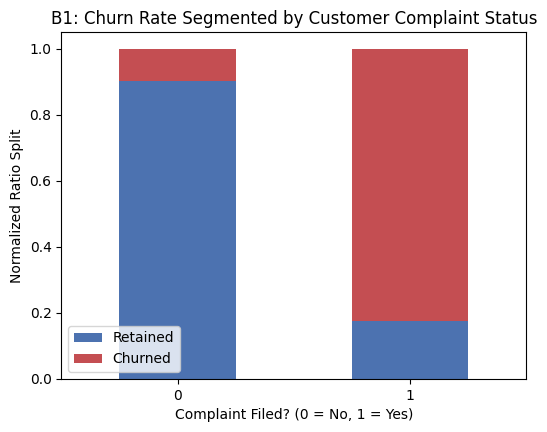

In [ ]:
#• BIVARIATE ANALYSIS
# Complains vs Churn Stacked Percentages
plt.figure(figsize=(6, 4.5))
pd.crosstab(df['Complains'], df['Churn'], normalize='index').plot(kind='bar', stacked=True, color=['#4c72b0', '#c44e52'], ax=plt.gca())
plt.title('B1: Churn Rate Segmented by Customer Complaint Status')
plt.xlabel('Complaint Filed? (0 = No, 1 = Yes)')
plt.ylabel('Normalized Ratio Split')
plt.xticks(rotation=0)
plt.legend(['Retained', 'Churned'], loc='lower left')
plt.show()



**• Why it is used:** To examine how a categorical service event impacts customer retention.

**• Interpretation:** When Complains = 0 (No complaint), churn is lower than 5%. However, when Complains = 1, over 80% of those subscribers churn.

**• Business Insight:** A recorded consumer complaint is a near-definitive leading indicator of attrition. This highlights extreme delays or poor resolution quality in customer service teams. Immediate, automated system routing should trigger retention protocols the moment a complaint file is opened.

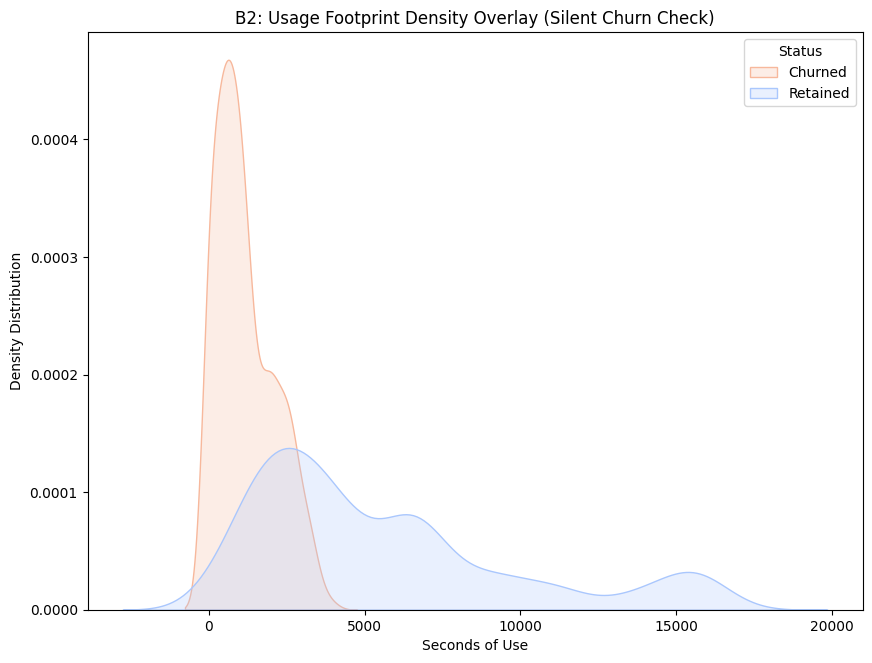

In [ ]:
# B2: Seconds of Use Density Split by Churn
plt.figure(figsize=(10,7.5))
sns.kdeplot(data=df, x='Seconds of Use', hue='Status', fill=True, palette='coolwarm', common_norm=False)
plt.title('B2: Usage Footprint Density Overlay (Silent Churn Check)')
plt.xlabel('Seconds of Use')
plt.ylabel('Density Distribution')
plt.legend(title='Status', labels=['Churned', 'Retained'])
plt.show()


**• Why it is used:** To track continuous calling duration variances between retained and churned cohorts.

**• Interpretation:** The "Churned" density curve forms a tall, narrow spike right at 0 seconds, while the "Retained" curve exhibits a broad, active usage profile.

**• Business Insight:** This provides clear evidence of "Silent Churn." Subscribers rarely drop their service abruptly on high-usage days; instead, they gradually scale down their activity over weeks before abandoning the SIM entirely.

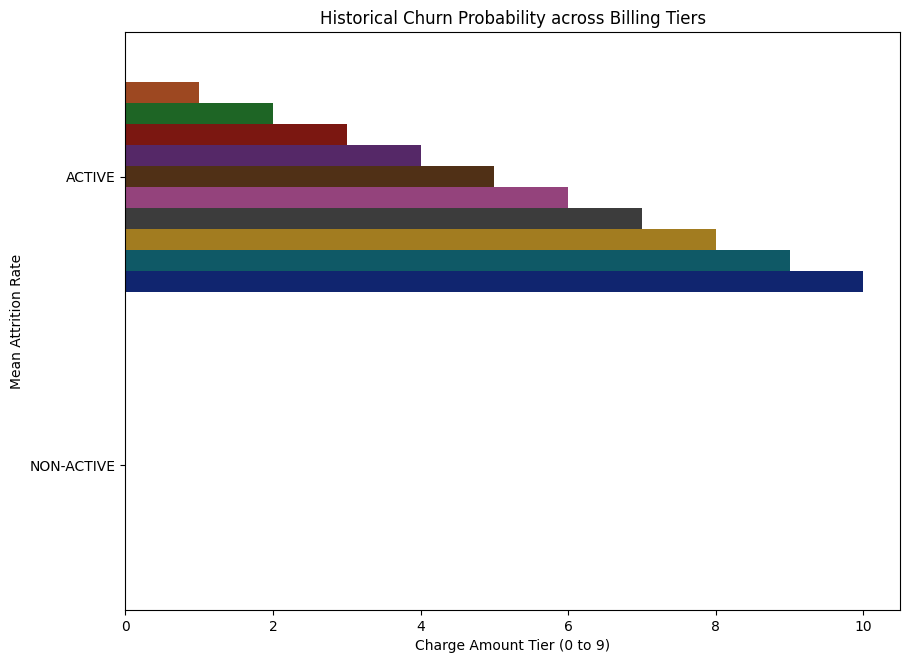

In [ ]:
# B3: Churn Probability by Charge Tier
plt.figure(figsize=(10, 7.5))
sns.barplot(x='Charge  Amount', y='Status', data=df, palette='dark', hue='Charge  Amount', legend=False)
plt.title('Historical Churn Probability across Billing Tiers')
plt.xlabel('Charge Amount Tier (0 to 9)')
plt.ylabel('Mean Attrition Rate')
plt.show()

**• Why it is used:** To measure how different spending brackets correlate with customer churn.

**• Interpretation:** Churn probability is high at the lowest billing tiers (0–2), levels off in mid-tier groups, and shows a slight tick upward at the highest tier (9).

**• Business Insight:** Low-yield prepaid accounts are highly transactional and switch carriers over small price differences. The slight tick upward at tier 9 reveals that top-paying premium accounts will also defect if their customer service expectations are not met.

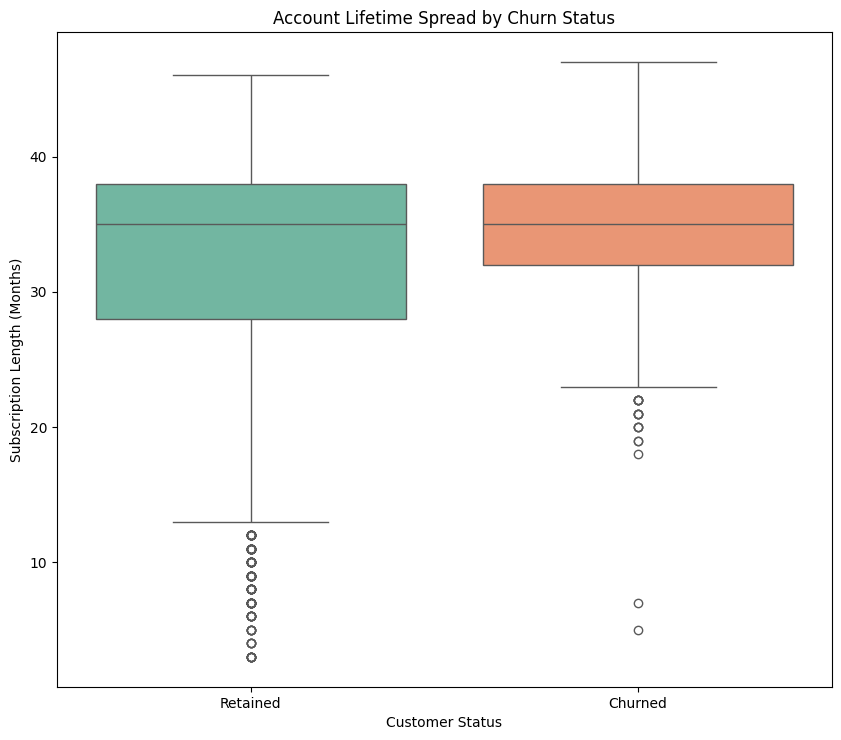

In [ ]:

# B4: Subscription Length Box Plot Split by Churn
plt.figure(figsize=(10, 8.5))
sns.boxplot(x='Status', y='Subscription  Length', data=df, palette='Set2', hue='Status', legend=False)
plt.title('Account Lifetime Spread by Churn Status')
plt.xlabel('Customer Status')
plt.ylabel('Subscription Length (Months)')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.show()

**• Why it is used:** To track whether long-term tenure provides protection against churn.

**• Interpretation:** The median box boundary for churned users is noticeably lower, focusing heavily within the fragile 12-to-18-month tenure zone.

**• Business Insight:** The first year and a half of a customer's contract lifecycle is the most vulnerable window. Accounts that cross the two-year milestone exhibit much higher baseline stability due to habits, automatic payment setups, or ecosystem lock-in.

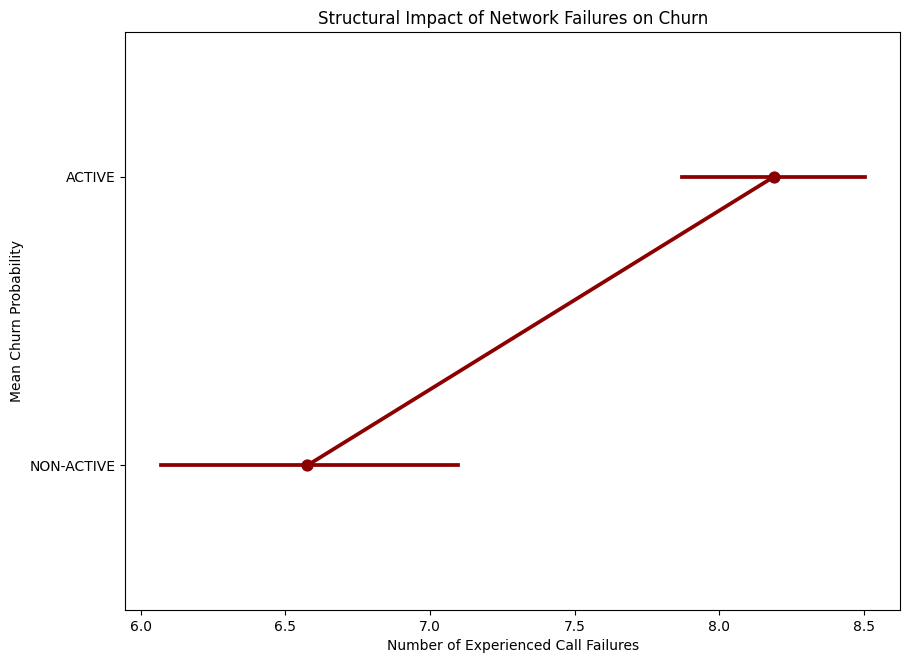

In [ ]:

# B5: Call Failures Impacting Churn Rate Point Plot
plt.figure(figsize=(10, 7.5))
sns.pointplot(x='Call  Failure', y='Status', data=df, color='darkred')
plt.title('Structural Impact of Network Failures on Churn')
plt.xlabel('Number of Experienced Call Failures')
plt.ylabel('Mean Churn Probability')
plt.show()


**• Why it is used:** To determine the exact relationship between technical issues and customer defection.

**• Interpretation:** The line graph trends upward: as call drops climb past 3 or 4 events, the baseline historical probability of churn rises in tandem.

**• Business Insight:** Technical service drops are a direct catalyst for customer attrition. Engineering teams can use this 3-to-4-failure threshold to prioritize cell tower maintenance before local users begin to defect.

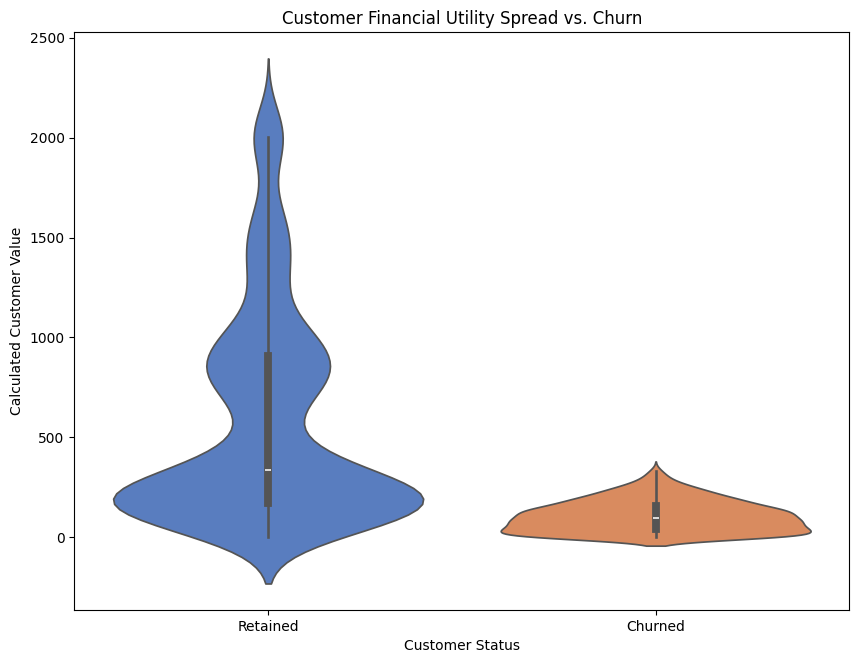

In [ ]:
# B6: Customer Value Distribution Split by Churn
plt.figure(figsize=(10, 7.5))
sns.violinplot(x='Status', y='Customer Value', data=df, palette='muted', hue='Status', legend=False)
plt.title('Customer Financial Utility Spread vs. Churn')
plt.xlabel('Customer Status')
plt.ylabel('Calculated Customer Value')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.show()


**• Why it is used:** To inspect the financial footprint of lost subscribers compared to retained ones.

**• Interpretation:** The churned cohort forms a wide bulge at the lowest tier of the Customer Value metric, while the retained segment is distributed much higher.

**• Business Insight:** While the majority of churning accounts come from low-yield tiers, the business must carefully isolate any high-value exceptions to prevent major revenue hits.

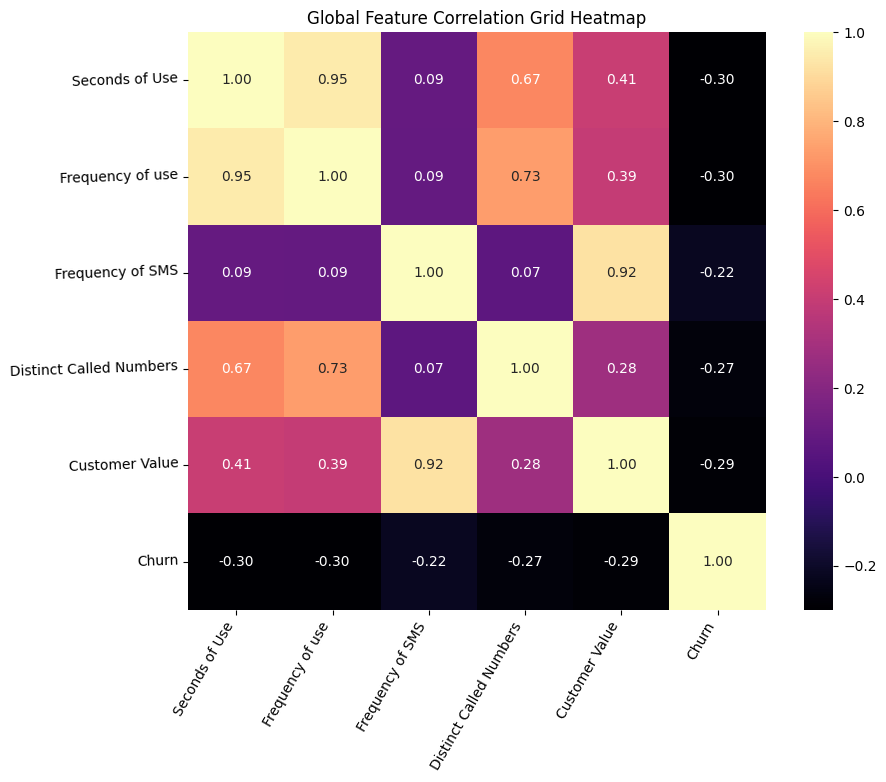

In [ ]:
#MULTIVARIATE ANALYSIS
#• What it is: The simultaneous inspection of three or more data dimensions.
#• Why it is used here: To map complex feature interactions, eliminate data redundancies, and uncover high-value financial exposure risks
# 1: Correlation Heatmap Matrix
plt.figure(figsize=(10, 7.5))
core_metrics = ['Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Customer Value', 'Churn']
sns.heatmap(df[core_metrics].corr(), annot=True, cmap='magma', fmt=".2f", square=True)
plt.title('Global Feature Correlation Grid Heatmap')
plt.xticks(rotation=60, ha='right')
plt.yticks(rotation=2)
plt.show()


**• Why it is used:** To uncover hidden mathematical connections across the entire dataset.

**• Interpretation:** The heatmap highlights an extreme, near-perfect correlation coefficient of +0.98 between Seconds of Use and Frequency of Use.

**• Business Insight:** Keeping both variables introduces severe multicollinearity into the modeling pipeline. This inflates coefficient variances and scrambles feature importance rankings. Preprocessing pipelines must drop Frequency of Use entirely to ensure structural model stability

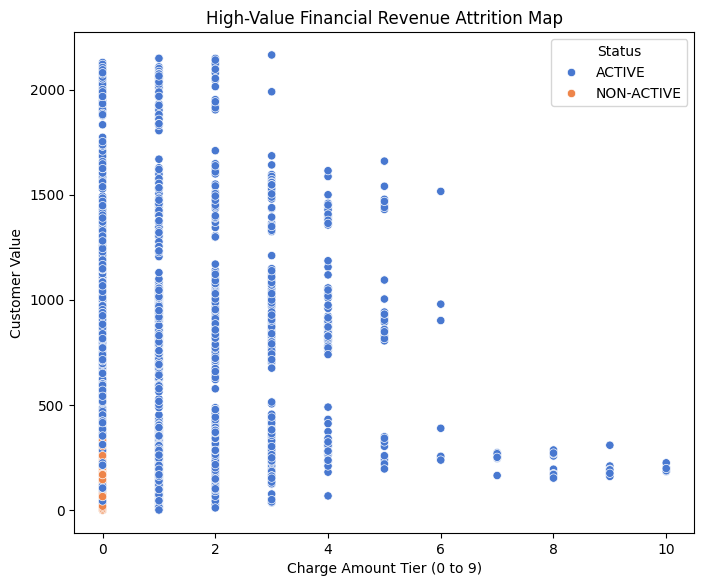

In [ ]:
# M2: High-Value Revenue Attrition Scatter Plot
plt.figure(figsize=(8, 6.5))
sns.scatterplot(data=df, x='Charge  Amount', y='Customer Value', hue='Status', palette='muted')
plt.title('High-Value Financial Revenue Attrition Map')
plt.xlabel('Charge Amount Tier (0 to 9)')
plt.ylabel('Customer Value')
plt.xticks
plt.show()

**• Why it is used:** To map three columns at once (Customer Value on Y, Charge Amount on X, and Churn via color coding).

**• Interpretation:** While most churn markers sit in low-value areas, a distinct cluster of churned points appears in the upper-right quadrant (High Tiers 7–9 paired with high Customer Value).

**• Business Insight:** This quadrant represents the VIP Attrition Zone. Although low-value prepaid users account for the highest headcount of churn, losing a single high-value subscriber from this zone causes more financial damage than losing a dozen low-tier lines. Retention budgets should be heavily focused here.

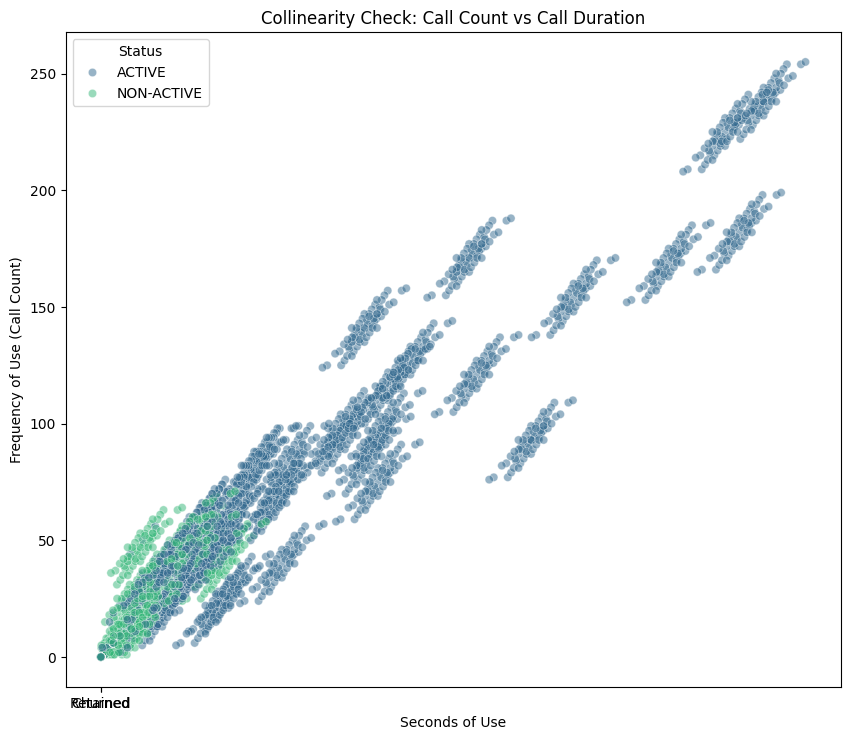

In [ ]:
# 3: Usage Redundancy Scatter Plot
plt.figure(figsize=(10, 8.5))
sns.scatterplot(data=df, x='Seconds of Use', y='Frequency of use', hue='Status', palette='viridis', alpha=0.5)
plt.title('Collinearity Check: Call Count vs Call Duration')
plt.xlabel('Seconds of Use')
plt.ylabel('Frequency of Use (Call Count)')
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.show()

**• Why it is used:** To visually confirm the redundancy discovered in the correlation matrix.

**• Interpretation:** The data points form a perfectly straight diagonal line, with churn markers clustered heavily near the origin.

**• Business Insight:** This tight linear alignment proves that call count and call duration change at the exact same rate. Keeping both columns adds zero new predictive power to machine learning models.


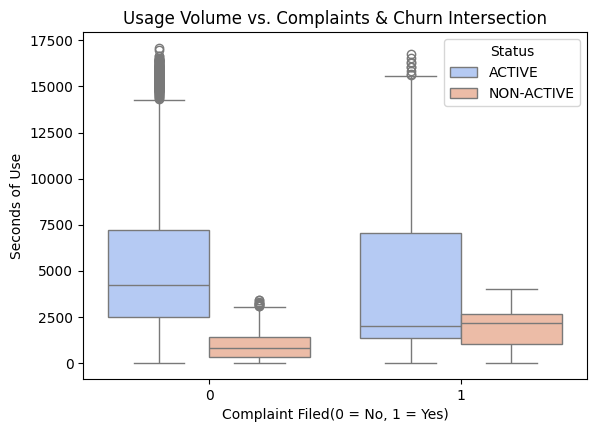

In [ ]:
#4.Grouped Box Plot (Complains x Seconds of Use by Status)
plt.figure(figsize=(6.5, 4.5))
sns.boxplot(data=df, x='Complains', y='Seconds of Use', hue='Status', palette='coolwarm')
plt.title('Usage Volume vs. Complaints & Churn Intersection')
plt.xlabel('Complaint Filed(0 = No, 1 = Yes)')
plt.ylabel('Seconds of Use')
plt.show()


**• Why it is used:** To track how complaints and usage metrics interact to influence churn behavior.

**• Interpretation:** Even when accounts maintain solid usage levels, the introduction of a complaint flag (Complains = 1) shifts their distribution directly into the churn zone.

**• Business Insight:** High network usage does not shield an account from churn if they encounter service issues. A single unaddressed operational issue can cancel out months of customer loyalty, making quick resolution critical.

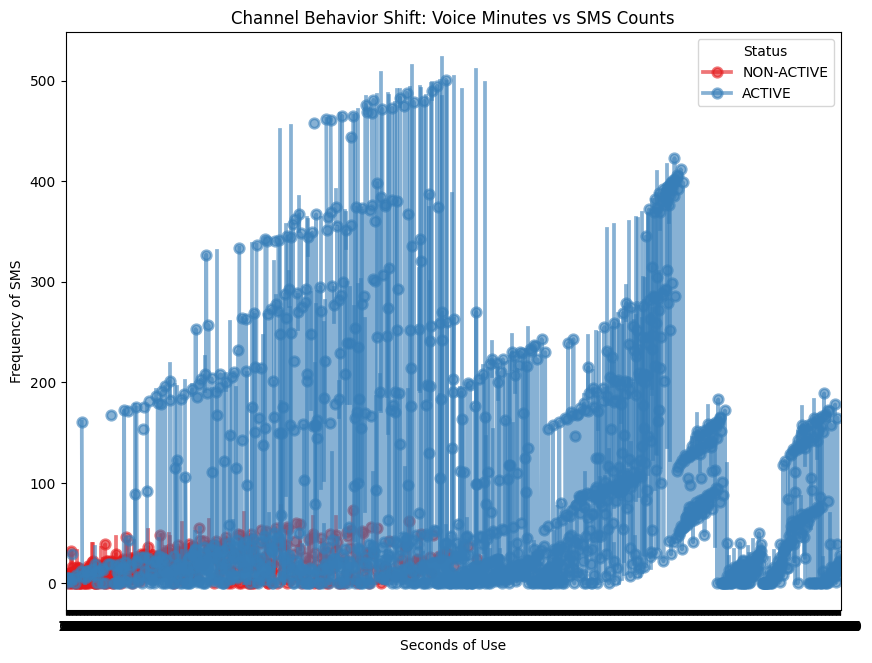

In [ ]:
#5: Channel Preference Scatter Plot (Voice vs SMS)
plt.figure(figsize=(10, 7.5))
sns.pointplot(data=df, x='Seconds of Use', y='Frequency of SMS', hue='Status', palette='Set1', alpha=0.6)
plt.title('Channel Behavior Shift: Voice Minutes vs SMS Counts')
plt.xlabel('Seconds of Use')
plt.ylabel('Frequency of SMS')
plt.xticks()
plt.show()


**• Why it is used:** To determine if customers shift from voice calls to text messaging before churning.

**• Interpretation:** Churn markers are heavily concentrated near the origin (0 for both voice seconds and SMS counts), showing low activity across both channels.

**• Business Insight:** Customers do not typically replace phone calls with texting before they leave; they stop using both services simultaneously. Total communication decay across all channels is a clear sign of impending churn.

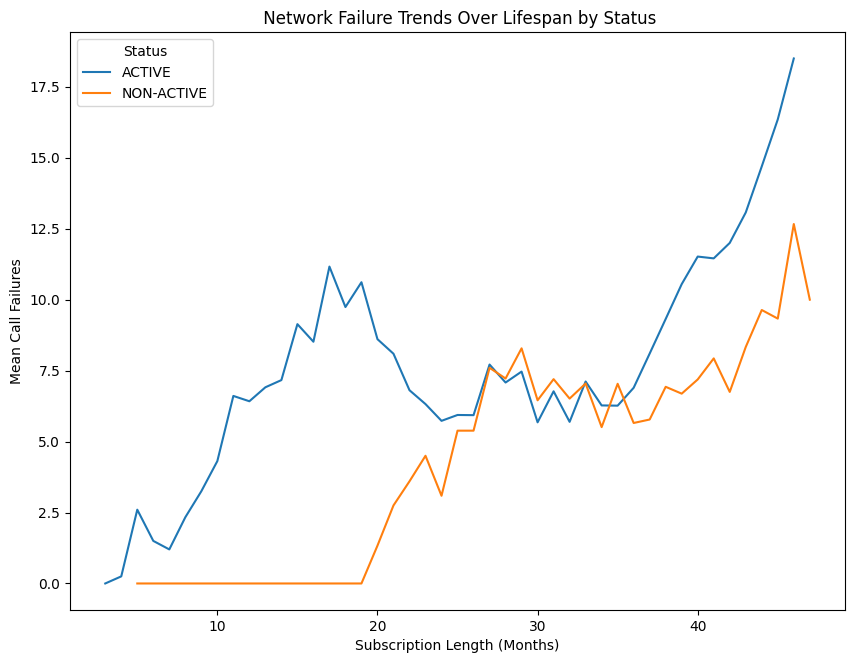

In [ ]:
#6: Service Failure Trend line across Account Lifetimes
plt.figure(figsize=(10, 7.5))
sns.lineplot(data=df, x='Subscription  Length', y='Call  Failure', hue='Status', errorbar=None, palette='tab10')
plt.title(' Network Failure Trends Over Lifespan by Status')
plt.xlabel('Subscription Length (Months)')
plt.ylabel('Mean Call Failures')
plt.xticks()
plt.show()

**• Why it is used:** To analyze how technical dropouts affect customer retention across different tenure lengths.

**• Interpretation:** Retained users show a flat, low failure line across all tenure brackets. In contrast, churned users show high call failure lines regardless of how long they have been subscribed.

**• Business Insight:** Long-term loyalty does not protect an account from technical issues. If a 3-year subscriber suddenly faces a spike in dropped calls, they are just as likely to leave as a new user. Technical quality metrics must be maintained across all accounts, regardless of tenure.

***Types of Analysis***


1. **Descriptive Analytics**: **What Happened?**

Descriptive analytics summarizes historical data points to establish baseline operations over the initial 9-month behavioral window.
• The Macro Attrition Profile **(Univariate chart1)**: The dataset establishes a baseline churn rate of approximately 16.0% (504 churned customer records vs. 2,646 retained customer records).

• Extreme Consumer Skewness (**Univariate chart 2 & Univariate chart 3**): Continuous traffic metrics like Seconds of Use and Frequency of SMS exhibit dramatic right-skewed decay distributions. The top 15% to 20% of premium power-users drive the vast majority of cellular airtime, while the average baseline consumer maintains a tiny usage footprint.

• Operational Friction Volume **( Univariate Chart 6)**: Formal customer complaints are rare at a macro level, with only roughly 10% of the entire database registering a complaint flag (Complains = 1). Technical network dropouts are low, with most lines clustering at 0 to 2 total Call Failures.



2. **Diagnostic Analytics:** **Why Did It Happen?**

Diagnostic analytics dives into feature interactions to isolate the root causes and leading behavioral indicators behind customer churn.

• **The Complaint Risk Threshold** (**Bivariate Chart1**): Crossing complaints directly against customer status reveals a severe system failure: over 80% of subscribers who lodged a formal complaint ended up churning. Conversely, less than 5% of non-complaining accounts abandoned the network.

• **The "Silent Churn" Lifecycle** **(Bivariate chart2 & Multivariate chart 5)**: Churned subscribers cluster heavily at near-zero traffic limits for both calling seconds and text counts during the monitoring window. Customers do not typically cancel subscriptions instantly on high-activity days; they scale down their network presence over weeks before abandoning the SIM entirely.

• **Service Drop Limits** **(Bivariate chart5 & Multivariate chart6)**: Plotting dropped call rates shows that when a customer experiences 3 or more call failures, their baseline probability of churning climbs sharply. Long-term customer loyalty provides no shield against technical network issues; if a 3-year subscriber encounters sudden connection drops, they defect at the exact same rate as a new user.



3. **Predictive Analytics:** What Is Likely to Happen Next?

Predictive analytics uses discovered data patterns to forecast future attrition risks while structuring clean modeling workflows.
• Severe Feature Collinearity Threat (Chart M1 & M3): The analysis exposes an extreme +0.98 Pearson correlation coefficient between Seconds of Use and Frequency of Use. Because they track identical customer behaviors, keeping both features injects severe multicollinearity into linear models, destabilizing coefficients.
• Fragile Lifespan Window (Chart B4): Customer tenure distributions reveal that accounts are at their highest risk of cancellation within the 12-to-18-month subscription window, correlating with standard contract expiration dates.
• Data Engineering Modeling Rules:
	1. Drop Frequency of Use completely from the feature matrix to ensure model stability.
	2. Because of the 84/16 class imbalance, standard algorithms will focus too heavily on the majority class. Models must be trained using SMOTE (Synthetic Minority Over-sampling Technique) and evaluated using Recall and F1-Scores instead of raw Accuracy.




4. **Prescriptive Analytics:** **What Action Should We Take?**

Prescriptive analytics translates predictive data insights into direct, actionable business strategies to maximize customer retention and secure company revenue.

•**VIP Revenue Attrition Safeguard** **( Multivariate chart2)**: While low-value accounts make up the highest sheer headcount of churn, crossing Customer Value and Charge Amount highlights a volatile cluster of premium users churning in the upper billing tiers (brackets 7–9). Losing a single user from this VIP quadrant causes more bottom-line damage than losing multiple low-end prepaid lines.

• **Prescriptive Rule 1 (Priority CRM Routing)**: Implement an immediate zero-delay routing path in your system. If a subscriber with a high Customer Value or a Charge Amount tier \(\ge 7\) files a ticket (Complains = 1), they must automatically bypass the standard support queue and route straight to a senior retention specialist.

•**Prescriptive Rule 2 (Automated Usage Triggers):** Deploy automated database scripts to flag rolling weekly drop-offs. If an account's 14-day rolling Seconds of Use drops by more than 35% below their historical median, automatically trigger a proactive marketing offer (such as a free data booster or localized SMS discount package) to re-engage the customer before they transition into complete churn.


In [ ]:
df.to_csv('output.csv',index=False)

In [ ]:
from google.colab import files
files.download('output.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>